# AI Agents

## 7.1 Ai agents tools - normal python function 

In [4]:
from langchain.tools import tool
@tool
def send_email(email:str):
    ### send logic 
    """I can send email to any email -address"""
    return {"message": "email send successfullt"}

In [5]:
send_email.invoke({"email":"bipul@gmail.com"})

{'message': 'email send successfullt'}

####7.2 Definning create agents

In [6]:
from langchain.agents import create_agent

In [18]:
import os
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()
print("call begin ")
llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    api_key=os.getenv("GOOGLE_API_KEY"),
    temperature=0.7,
    timeout = 20,
    max_retries = 0,
    max_tokens = 100

)
print("taking to long to respond")

response = llm.invoke("Hi! Would u like to be my ai agents partner")

print(response.content)

call begin 
taking to long to respond


GoogleAPIError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [ ]:

agent = create_agent(
    system_prompt="""
    You are a email sending agent, based on user request you can draft a mail and send to email address using 'send_email'""",
    model = llm,
    tools = [send_email]
)

NameError: name 'llm' is not defined

In [27]:
import os 
from dotenv import load_dotenv
from langchain_groq import ChatGroq

print("Api had been called")
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    api_key=os.getenv("GROQ_API_KEY"),
    temperature= 0.8,
    timeout= 20,
    max_retries= 0,
    max_tokens= 120
)

print("API called successfully")



Api had been called
API called successfully


In [28]:
response = llm.invoke("hi")

In [29]:
print(response.content)

Hello! 👋 How can I help you today?


In [30]:
from langchain.agents import create_agent

In [41]:
@tool
def send_email(email: str):
    "sent email as per request"
    print("[Tool] called", email)
    return {"Message": "Email sent succesfully"}

In [39]:
agent = create_agent(
    system_prompt="You are a email sending agents based on the user request you can draft a mail and sent to " \
    "email address using send_email",
    model = llm,
    tools =[send_email]
)

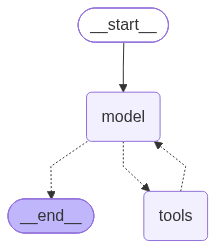

In [34]:
agent 

In [42]:
que = "I want to send a leave request to this mail address, 'email@gmail.com"
response = agent.invoke({"role":"user", "content": que})

In [43]:
response 

{'messages': [AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to parse user request. The user says: "You are a email sending agents based on the user request you can draft a mail and sent to email address using send_email". The user hasn\'t provided a specific email content or address. Perhaps they want me to draft and send an email? But no details given. Could be a system prompt? Wait the conversation: The user says "You are a email sending agents based on the user request you can draft a mail and sent to email address using send_email". That seems like a system instruction. But we are ChatGPT with the'}, response_metadata={'token_usage': {'completion_tokens': 120, 'prompt_tokens': 143, 'total_tokens': 263, 'completion_time': 0.124862737, 'completion_tokens_details': {'reasoning_tokens': 118}, 'prompt_time': 0.00792888, 'prompt_tokens_details': None, 'queue_time': 0.386192876, 'total_time': 0.132791617}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 